# Shape from Heat Conduction and Shading — simulation pipeline

Recover surface normals (p, q) from the cotangent Laplacian **L** and shading **η**.

## Setup

In [1]:
import os
import sys
import torch
import torch.optim as optim
import tqdm
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize


workspace_path = os.path.dirname(os.path.dirname(os.path.abspath("__file__")))
sys.path.append(workspace_path)

from lib.utils_sim import *

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


ModuleNotFoundError: No module named 'lib.utils'

### Parameters

Geometry, light source direction (θ, φ), and candidate count for near-planar patch selection.

In [ ]:
sim_params = {
    'sim_width'  : 128,
    'sim_height' : 128,
    'obj_name' : 'igea-60kf',
    'obj_zdist': 100,
    'theta_s': 30,
    'phi_s'  :  180,
    'candidates' : 55,
    }
width  = sim_params['sim_width']
height = sim_params['sim_height']

### Mesh Construction

Ray-cast an `.obj` mesh onto a regular grid to obtain a depth map, then compute ground-truth normals and Laplacian.

Scaled mesh to be within coords: Min: [-0.65253807 -0.89659005 -0.81862672] and Max: [0.61570752 0.92721543 1.        ]
Constructed a camera mesh for igea-60kf and saved it for future reuse at /path/to/shape-from-heat-conduction-and-shading/objs/igea-60kf_camera_128x128_100.obj.


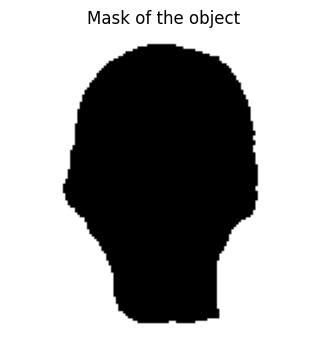

In [ ]:
if sim_params['obj_name'] is not None:
    verts_np, faces_np, mask_flat = construct_camera_mesh(
        sim_params['obj_name'], width, height, sim_params['obj_zdist'], return_mask=True
    )
    mask2d = mask_flat.reshape(height, width)
else:
    verts_np, faces_np, ii, jj = create_reg_tri_mesh_from_camera(width, height)
    verts_np[:, 2] = -(verts_np[:, 0]**2 + verts_np[:, 1]**2)
    mask2d = np.zeros((height, width), dtype=np.uint8)

pixel_pitch = verts_np[1, 0] - verts_np[0, 0]
mesh = trimesh.Trimesh(vertices=verts_np, faces=faces_np)

plt.figure(figsize=(4, 4))
plt.imshow(mask2d, cmap='gray', origin='lower')
plt.title('Mask of the object')
plt.axis('off')
plt.show()

### Variables

Key variables computed from the mesh and `sim_params`:

| Variable | Shape | Description |
|---|---|---|
| `p_gt`, `q_gt` | (H×W,) | GT surface gradients ∂z/∂x, ∂z/∂y |
| `ps_gt`, `qs_gt` | scalar | GT light direction (gradient form) |
| `lap_gt` | (N_inner, 6) | GT cotangent Laplacian weights |
| `eta_gt_2d` | (H, W) | GT shading image |
| `eta_array` | (N_inner,) | Flat shading for inner pixels |
| `pq_array` | (N_inner, 2) | Flat (p, q) for inner pixels |

ps_gt: -0.5773502691896256, qs_gt: 7.070501591499378e-17


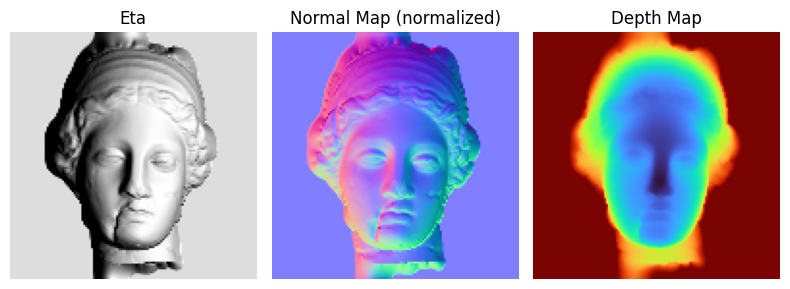

In [ ]:
# Normal, p, q
normal_gt = compute_finite_difference_normals(verts_np, 128, 128, "fwd")
pq_gt = normal_gt / normal_gt[:, 2:3]
p_gt = pq_gt[:, 0]
q_gt = pq_gt[:, 1]
p_gt_2d = p_gt.reshape((height, width))
q_gt_2d = q_gt.reshape((height, width))
pq_gt_2d = pq_gt.reshape((height, width, 3))
pq_gt_2d_norm = pq_gt_2d / np.linalg.norm(pq_gt_2d, axis=-1, keepdims=True)

# Source direction
theta_s_gt = np.deg2rad(sim_params['theta_s'])
phi_s_gt   = np.deg2rad(sim_params['phi_s'])
sx_gt = math.sin(theta_s_gt) * math.cos(phi_s_gt)
sy_gt = math.sin(theta_s_gt) * math.sin(phi_s_gt)
sz_gt = math.cos(theta_s_gt)
ps_gt = sx_gt / sz_gt
qs_gt = sy_gt / sz_gt
s_vec_gt = np.array([ps_gt, qs_gt, 1.0])
print(f"ps_gt: {ps_gt}, qs_gt: {qs_gt}")

# Eta
eta_gt = compute_shading_value(p_gt, q_gt, ps_gt, qs_gt)
eta_gt_2d = eta_gt.reshape((height, width))

# Laplacian
lap_gt = cotan_laplacians_from_pq_np(pq_gt, width, height)
lap_gt_reshaped = lap_gt.reshape(126, 126, 6)

# depth
depth_values = verts_np[:, 2]
depth_map_gt = depth_values.reshape((height, width))

# Normal map
normal_map_norm = ((pq_gt_2d_norm + 1) / 2) * 255
normal_map_norm = normal_map_norm.astype(np.uint8)

fig, ax = plt.subplots(1, 3, figsize=(8, 6))
ax[0].imshow(eta_gt_2d, cmap='gray', origin='lower'); ax[0].set_title('Eta'), ax[0].axis('off')
ax[1].imshow(normal_map_norm, origin='lower'); ax[1].set_title('Normal Map (normalized)'), ax[1].axis('off')
ax[2].imshow(depth_map_gt, cmap='turbo', origin='lower'); ax[2].set_title('Depth Map'), ax[2].axis('off')

plt.tight_layout()
plt.show()

## Pre-process

Compute ground-truth inputs from the mesh: cotangent Laplacian **L** and shading **η**.

### Ground-Truth Laplacian (L)

6-component cotangent weights per inner pixel, derived from GT normals (p, q).

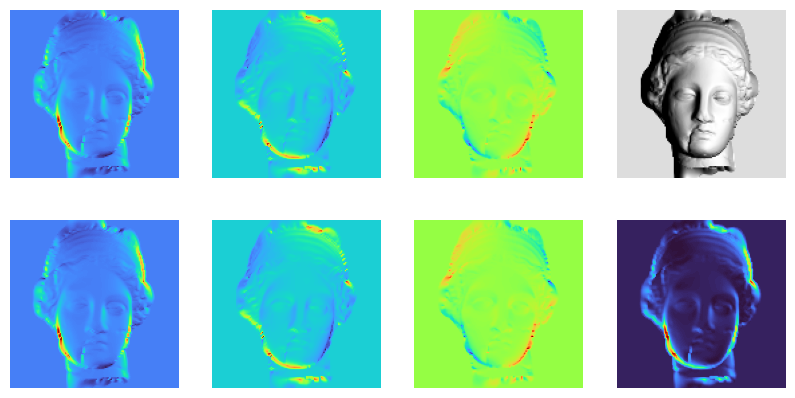

In [ ]:
# Plot the GT Laplacian
fig, ax = plt.subplots(2, 4, figsize=(10, 5))
ax[0, 0].imshow(lap_gt_reshaped[..., 0], cmap='turbo', origin='lower'), ax[0, 0].axis('off')
ax[0, 1].imshow(lap_gt_reshaped[..., 1], cmap='turbo', origin='lower'), ax[0, 1].axis('off')
ax[0, 2].imshow(lap_gt_reshaped[..., 2], cmap='turbo', origin='lower'), ax[0, 2].axis('off')
ax[1, 0].imshow(lap_gt_reshaped[..., 3], cmap='turbo', origin='lower'), ax[1, 0].axis('off')
ax[1, 1].imshow(lap_gt_reshaped[..., 4], cmap='turbo', origin='lower'), ax[1, 1].axis('off')
ax[1, 2].imshow(lap_gt_reshaped[..., 5], cmap='turbo', origin='lower'), ax[1, 2].axis('off')
ax[0, 3].imshow(eta_gt_2d, cmap='gray', origin='lower'), ax[0, 3].axis('off')
ax[1, 3].imshow(lap_gt_reshaped.sum(axis=2), cmap='turbo', origin='lower'), ax[1, 3].axis('off')
plt.show()

### Ground-Truth Shading (η)

η = (p·pₛ + q·qₛ + 1) / (‖n‖·‖s‖),  clamped to [0, 1].

### Visualization

η ∈ [0, 1]: bright = surface facing the light, dark = surface facing away.

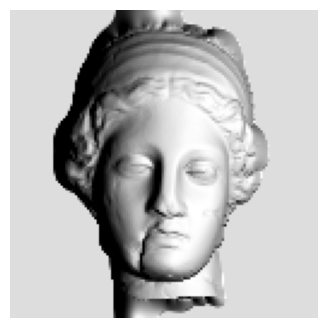

In [ ]:
# Visualize the final eta
plt.figure(figsize=(4,4))
plt.imshow(eta_gt_2d, cmap='gray', origin='lower')
plt.axis('off')
plt.show()

## Step 1 — Light Source Estimation

Estimate the light direction (pₛ, qₛ) from near-planar patches.

1. Find flat regions in **L** (`find_flat_regions`)
2. For each patch, compute two candidate normal pairs (p, q) from the Laplacian
3. Select the candidate consistent with η
4. Run RANSAC to robustly fit (pₛ, qₛ)
5. Iterate: refine normals → re-estimate light → repeat

### Near-Planar Patch Selection

`find_flat_regions` picks pixels where the Laplacian magnitude is small (≈ planar surface).  
`extract_candidates` filters the top-K patches most consistent with the observed shading.

### Two-Solution Ambiguity

The cotangent Laplacian yields **two candidate pairs** (p₁, q₁) and (p₂, q₂) per pixel.  
Pixels where the solution is undefined (NaN) are flagged as **invalid**.

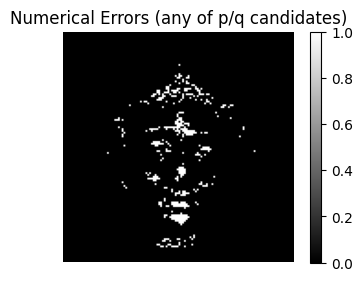

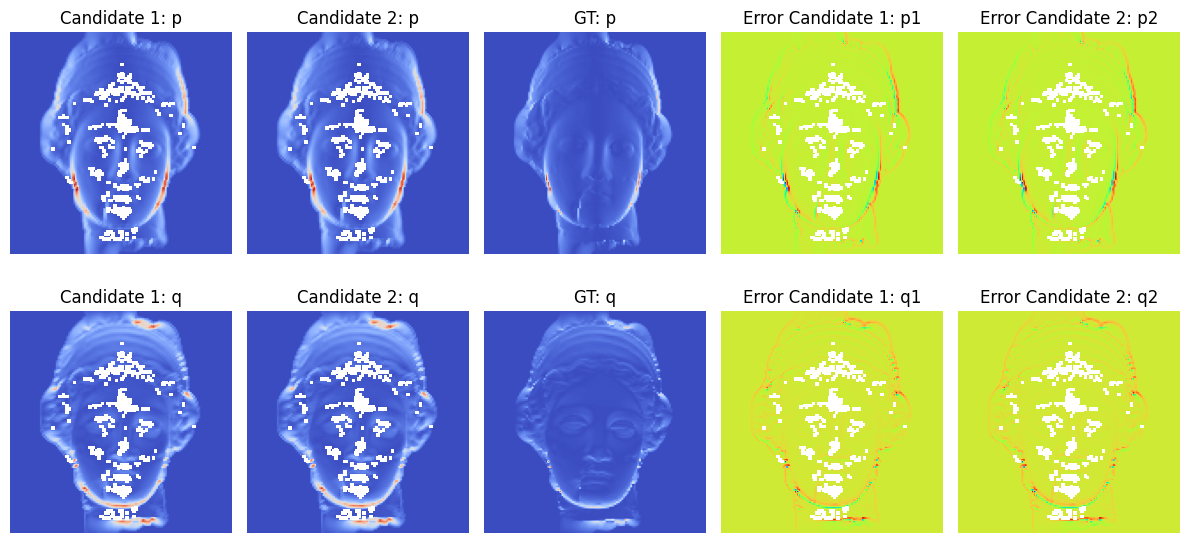

In [ ]:
(p1, q1), (p2, q2) = compute_p_q_from_w_v3(lap_gt)

# Reshape for visualization
p1_2d = p1.reshape((height-2, width-2))
q1_2d = q1.reshape((height-2, width-2))
p2_2d = p2.reshape((height-2, width-2))
q2_2d = q2.reshape((height-2, width-2))
nan_map = np.isnan(p1_2d) | np.isnan(q1_2d) | np.isnan(p2_2d) | np.isnan(q2_2d)

# Visualize NaN map
plt.figure(figsize=(4,3))
plt.imshow(nan_map, cmap='gray', origin='lower')
plt.title('Numerical Errors (any of p/q candidates)')
plt.colorbar()
plt.axis('off')
plt.show()

# Visualize candidates
fig, ax = plt.subplots(2, 5, figsize=(12, 6))
# --- p (top row) ---
ax[0, 0].imshow(np.abs(p1_2d), cmap='coolwarm', origin='lower'); ax[0, 0].set_title('Candidate 1: p'), ax[0, 0].axis('off')
ax[0, 1].imshow(np.abs(p2_2d), cmap='coolwarm', origin='lower'); ax[0, 1].set_title('Candidate 2: p'), ax[0, 1].axis('off')
ax[0, 2].imshow(np.abs(p_gt_2d[1:-1, 1:-1]), cmap='coolwarm', origin='lower'); ax[0, 2].set_title('GT: p'), ax[0, 2].axis('off')
ax[0, 3].imshow(np.abs(p1_2d) - np.abs(p_gt_2d[1:-1,1:-1]), cmap='turbo', origin='lower'); ax[0, 3].set_title('Error Candidate 1: p1'), ax[0, 3].axis('off')
ax[0, 4].imshow(np.abs(p2_2d) - np.abs(p_gt_2d[1:-1,1:-1]), cmap='turbo', origin='lower'); ax[0, 4].set_title('Error Candidate 2: p2'), ax[0, 4].axis('off')

# --- q (bottom row) ---
ax[1, 0].imshow(np.abs(q1_2d), cmap='coolwarm', origin='lower'); ax[1, 0].set_title('Candidate 1: q'), ax[1, 0].axis('off')
ax[1, 1].imshow(np.abs(q2_2d), cmap='coolwarm', origin='lower'); ax[1, 1].set_title('Candidate 2: q'), ax[1, 1].axis('off')
ax[1, 2].imshow(np.abs(q_gt_2d[1:-1, 1:-1]), cmap='coolwarm', origin='lower'); ax[1, 2].set_title('GT: q'), ax[1, 2].axis('off')
ax[1, 3].imshow(np.abs(q1_2d) - np.abs(q_gt_2d[1:-1,1:-1]), cmap='turbo', origin='lower'); ax[1, 3].set_title('Error Candidate 1: q1'), ax[1, 3].axis('off')
ax[1, 4].imshow(np.abs(q2_2d) - np.abs(q_gt_2d[1:-1,1:-1]), cmap='turbo', origin='lower'); ax[1, 4].set_title('Error Candidate 2: q2'), ax[1, 4].axis('off')

plt.tight_layout()
plt.show()

Both candidates are valid in magnitude — shading comparison is needed to resolve the sign ambiguity.

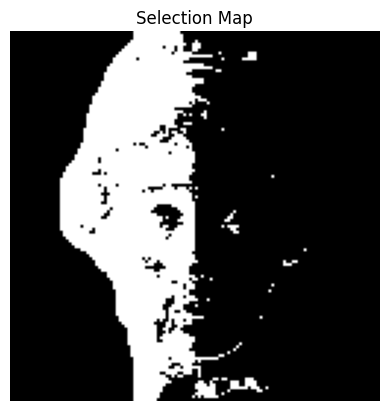

In [ ]:
eta1 = compute_shading_value(p1, q1, ps_gt, qs_gt)
eta2 = compute_shading_value(p2, q2, ps_gt, qs_gt)
eta_gt_2d_reshaped = eta_gt_2d[1:-1, 1:-1]
eta_gt_2d_flat = eta_gt_2d_reshaped.flatten()

e1 = abs(eta1 - eta_gt_2d_flat)
e2 = abs(eta2 - eta_gt_2d_flat)

mask = (e1 < e2)
p_selected = np.where(mask, p1, p2)
q_selected = np.where(mask, q1, q2)
selection_map = mask.astype(np.int32)
selection_map_2d = selection_map.reshape((height-2, width-2))

# Visualization just selection_map_2d
plt.imshow(selection_map_2d, cmap='gray', origin='lower')
plt.title('Selection Map')
plt.axis('off')
plt.show()

The better candidate is selected per pixel by `argmin |η_est − η_gt|`.  
Pixels near the degenerate line p = −(pₛ/qₛ)·q produce nearly equal errors — these are marked **ambiguous**.

### RANSAC + Iterative Refinement

`ransac_estimate_ps_qs_with_sign` fits (pₛ, qₛ) from candidate (p, q) vs η.  
`main_refinement` alternates per-pixel SLSQP optimization and RANSAC until convergence.

### Candidate Extraction

`find_flat_regions` returns pixel indices where `‖L‖` is small (near-planar).  
`extract_candidates` keeps the top-K patches with the lowest shading error, assembling `pq_array` and `eta_array` for RANSAC.

In [ ]:
id_planar, L_planar = find_flat_regions(lap_gt)

subset_init, scale = extract_candidates(id_planar, L_planar, eta_gt_2d, width, TOP_K=sim_params['candidates'])
print(f"Filtered candidates count: {len(subset_init)}")

pq_list = []
eta_list = []

for (pix_id, p, q, *_) in subset_init:
    row_in = (pix_id // (width-2)) + 1
    col_in = (pix_id %  (width-2)) + 1
    eta_in = eta_gt_2d[row_in, col_in]
    pq_list.append([p, q])
    eta_list.append(eta_in)

pq_array = np.array(pq_list, dtype=np.float64)
eta_array = np.array(eta_list, dtype=np.float64)

Filtered candidates count: 55


### Iterative Refinement Loop

`main_refinement` runs up to `max_iter` rounds:

1. **SLSQP** — optimize each patch pixel's (p, q) independently (per-pixel local minimum)
2. **RANSAC** — re-estimate (pₛ, qₛ) from the updated (p, q) vs η
3. **Convergence** — stop when total objective change < 1e-16

In [ ]:
subset_refined, ps_final, qs_final, residual = main_refinement(subset_init, pq_array, width, height, lap_gt, eta_array, max_iter=10)
print("Refinement Done")
print(f"Ground truth  : ps, qs = {ps_gt:.3f}, {qs_gt:.3f}")
print(f"After  refined: ps, qs = {ps_final:.3f}, {qs_final:.3f}")
print(f"Residual: {residual:.6f}")

# Compute the angler error
s_gt = np.array([ps_gt, qs_gt, 1.0])
s_est = np.array([ps_final, qs_final, 1.0])

s_gt_norm = s_gt / np.linalg.norm(s_gt)
s_est_norm = s_est / np.linalg.norm(s_est)

dot_product = np.dot(s_gt_norm, s_est_norm)
dot_product = np.clip(dot_product, -1.0, 1.0)

angle_error_rad = np.arccos(dot_product)
angle_error_deg = np.degrees(angle_error_rad)

print(f"Angular error in light source direction: {angle_error_deg:.3f} degrees")

Initial cost = 21.533523
Initial estimate (RANSAC)
    fell_back=False, inlier_ratio=0.600, residual=1.163462e-02
    ps, qs = -0.573, 0.011
    light(RANSAC): fell_back=False, inlier_ratio=0.309, residual=7.538067e-03
Iter 01 | Cost new = 0.971682 | inlier_ratio=0.309 | residual=7.538067e-03
    light(RANSAC): fell_back=False, inlier_ratio=0.309, residual=7.538067e-03
Iter 02 | Cost new = 0.971682 | inlier_ratio=0.309 | residual=7.538067e-03
Refinement Done
Ground truth  : ps, qs = -0.577, 0.000
After  refined: ps, qs = 0.569, -0.012
Residual: 0.007538
Angular error in light source direction: 59.638 degrees


## Step 2 — Dense Normal Initialization

Assign a normal (p, q) to every inner pixel using the estimated (pₛ, qₛ).

1. Pick the better Laplacian candidate by comparing η error per pixel
2. Fill **invalid** pixels (NaN) with local 10×10 neighborhood mean
3. Fill **ambiguous** pixels (|η₁ − η₂| < 0.03) with local 10×10 neighborhood mean

In [ ]:
import time
start_time = time.time()
subset, sign_map, invalid_map, ambiguous_map = extract_candidates_v3(
    lap_gt, eta_gt_2d, height, width, ps_final, qs_final, iters=100
)
end_time = time.time()
print(f"extract_candidates_v3 took {end_time - start_time:.4f} seconds")
print("Done.")

extract_candidates_v3 took 0.0589 seconds
Done.


#### Output Maps

| Map | dtype | Meaning |
|---|---|---|
| `sign_map` | uint8 | 0 = candidate 1 chosen, 1 = candidate 2 chosen |
| `invalid_map` | uint8 | 1 = NaN solution (excluded from optimization) |
| `ambiguous_map` | uint8 | 1 = both candidates give nearly equal η error |

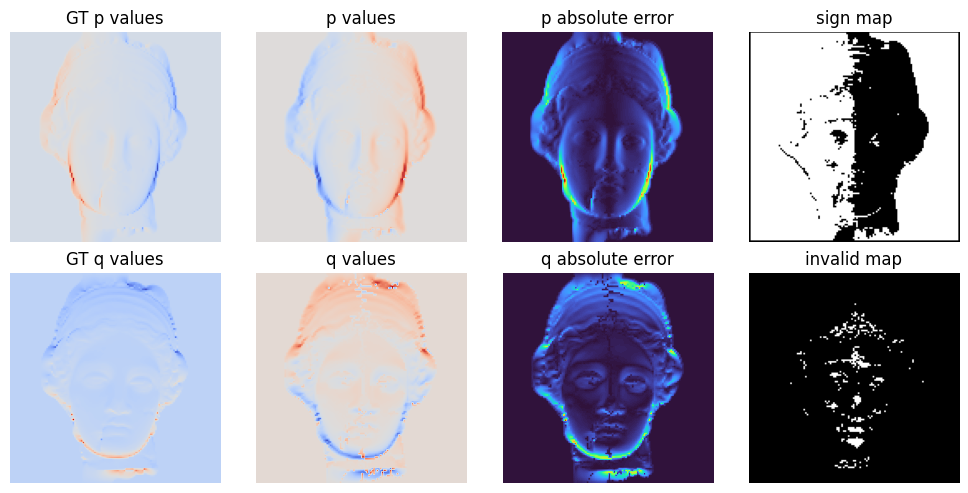

In [ ]:
# Visualize sign_map, ambiguous_map, invalid_map
subset_sorted = sorted(subset, key=lambda x: x[0])
p_array = np.array([x[1] for x in subset_sorted])
q_array = np.array([x[2] for x in subset_sorted])
p_array_2d = p_array.reshape((126, 126))
q_array_2d = q_array.reshape((126, 126))

pq_stack = np.stack([p_array, q_array, np.ones_like(p_array)], axis=1)
pq_init = pq_stack.reshape((126, 126, 3))

# Error
p_gt_crop = p_gt_2d[1:-1, 1:-1]
q_gt_crop = q_gt_2d[1:-1, 1:-1]
p_abs_error = np.abs(p_array_2d - p_gt_crop)
q_abs_error = np.abs(q_array_2d - q_gt_crop)

fig, ax = plt.subplots(2, 4, figsize=(10, 5))
ax[0, 0].imshow(p_gt_2d, origin='lower', cmap='coolwarm'); ax[0, 0].set_title('GT p values'), ax[0, 0].axis('off')
ax[0, 1].imshow(p_array_2d, origin='lower', cmap='coolwarm'); ax[0, 1].set_title('p values'), ax[0, 1].axis('off')
ax[0, 2].imshow(p_abs_error, origin='lower', cmap='turbo'); ax[0, 2].set_title('p absolute error'), ax[0, 2].axis('off')
ax[0, 3].imshow(sign_map, origin='lower', cmap='gray'); ax[0, 3].set_title('sign map'), ax[0, 3].axis('off')

ax[1, 0].imshow(q_gt_2d, origin='lower', cmap='coolwarm'); ax[1, 0].set_title('GT q values'), ax[1, 0].axis('off')
ax[1, 1].imshow(q_array_2d, origin='lower', cmap='coolwarm'); ax[1, 1].set_title('q values'), ax[1, 1].axis('off')
ax[1, 2].imshow(q_abs_error, origin='lower', cmap='turbo'); ax[1, 2].set_title('q absolute error'), ax[1, 2].axis('off')
ax[1, 3].imshow(invalid_map, origin='lower', cmap='gray'); ax[1, 3].set_title('invalid map'), ax[1, 3].axis('off')

plt.tight_layout()
plt.show()

### Verification — Candidate Selection

Reconstruct L̂ from the selected (p, q) and compare against GT L.  
A good match confirms that shading-based sign selection is working correctly.

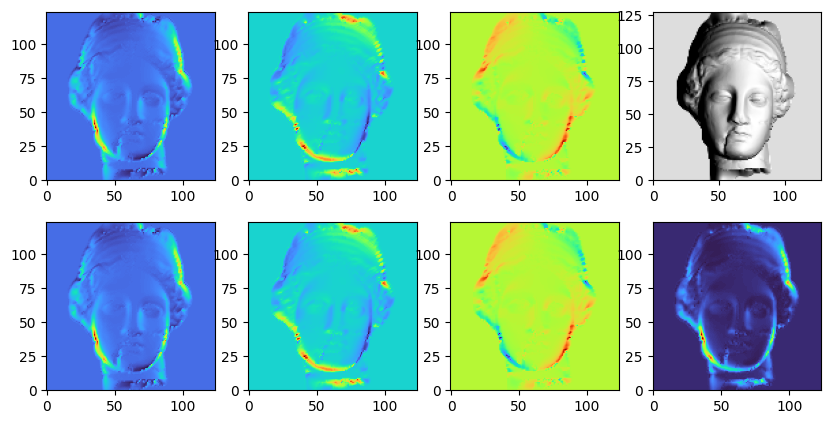

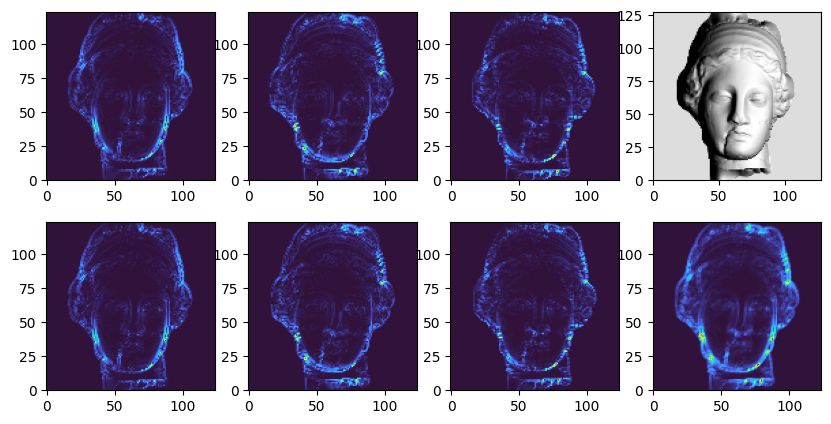

In [ ]:
# Plot the Laplacian
L_hat = cotan_laplacians_from_pq_np(pq_stack, width-2, height-2)
L_hat_reshaped = L_hat.reshape(124, 124, 6)
fig, ax = plt.subplots(2, 4, figsize=(10, 5))

# Plot the estimated Laplacian
ax[0, 0].imshow(L_hat_reshaped[..., 0], cmap='turbo', origin='lower')
ax[0, 1].imshow(L_hat_reshaped[..., 1], cmap='turbo', origin='lower')
ax[0, 2].imshow(L_hat_reshaped[..., 2], cmap='turbo', origin='lower')
ax[1, 0].imshow(L_hat_reshaped[..., 3], cmap='turbo', origin='lower')
ax[1, 1].imshow(L_hat_reshaped[..., 4], cmap='turbo', origin='lower')
ax[1, 2].imshow(L_hat_reshaped[..., 5], cmap='turbo', origin='lower')
ax[0, 3].imshow(eta_gt_2d, cmap='gray', origin='lower')
ax[1, 3].imshow(L_hat_reshaped.sum(axis=2), cmap='turbo', origin='lower')
plt.show()

# Compute Laplacian error
lap_gt_interior = lap_gt_reshaped[1:-1, 1:-1, :]
lap_gt_flat = lap_gt_interior.reshape(-1, 6)
lap_error = np.abs(lap_gt_flat - L_hat)
lap_error_reshaped = lap_error.reshape(height-4, width-4, 6)

fig, ax = plt.subplots(2, 4, figsize=(10, 5))
ax[0, 0].imshow(lap_error_reshaped[..., 0], cmap='turbo', origin='lower')
ax[0, 1].imshow(lap_error_reshaped[..., 1], cmap='turbo', origin='lower')
ax[0, 2].imshow(lap_error_reshaped[..., 2], cmap='turbo', origin='lower')
ax[1, 0].imshow(lap_error_reshaped[..., 3], cmap='turbo', origin='lower')
ax[1, 1].imshow(lap_error_reshaped[..., 4], cmap='turbo', origin='lower')
ax[1, 2].imshow(lap_error_reshaped[..., 5], cmap='turbo', origin='lower')
ax[0, 3].imshow(eta_gt_2d, cmap='gray', origin='lower')
ax[1, 3].imshow(lap_error_reshaped.sum(axis=2), cmap='turbo', origin='lower')
plt.show()


### Fill Invalid Pixels

Pixels where the Laplacian solution is NaN are replaced by the local neighborhood mean.

In [ ]:
invalid_in = invalid_map[1:-1, 1:-1]
p_2d = p_array.reshape((126, 126))
q_2d = q_array.reshape((126, 126))
p_filled = fill_invalid_by_mean(p_2d, invalid_in)
q_filled = fill_invalid_by_mean(q_2d, invalid_in)
p_array_1d = p_filled.flatten()
q_array_1d = q_filled.flatten()
pq_stack_filled = np.stack([p_array_1d, q_array_1d, np.ones_like(p_array_1d)], axis=1)


### Verification — After Filling Invalid

The mean-filled pixels should blend smoothly with their neighbors.  
Large errors here indicate that the surrounding valid region itself has systematic bias.

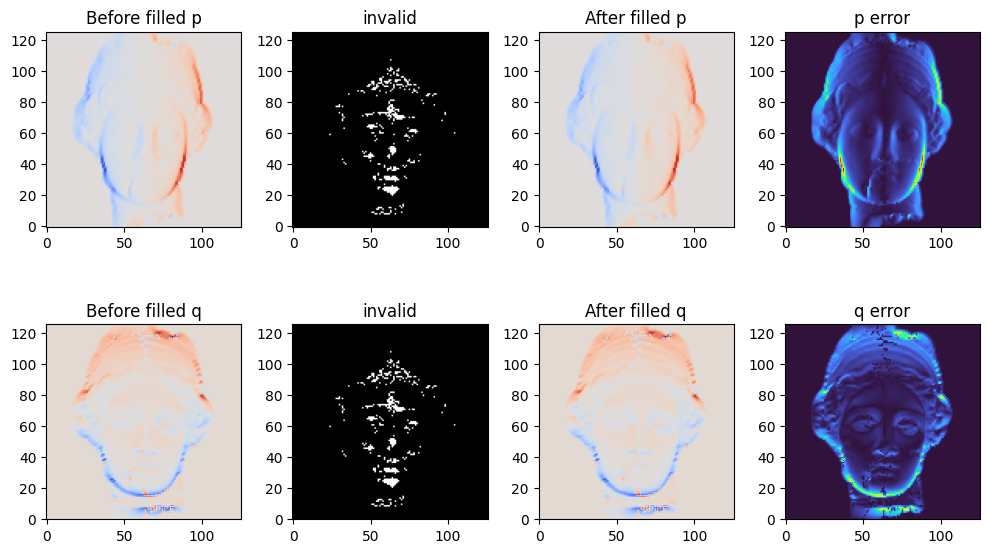

In [ ]:
# Error
p_error_filled = np.abs(p_filled - p_gt_crop)
q_error_filled = np.abs(q_filled - q_gt_crop)

fig, ax = plt.subplots(2, 4, figsize=(10,6))
ax[0,0].imshow(p_2d, origin='lower', cmap='coolwarm'); ax[0,0].set_title('Before filled p')
ax[0,1].imshow(invalid_in, origin='lower', cmap='gray'); ax[0,1].set_title('invalid')
ax[0,2].imshow(p_filled, origin='lower', cmap='coolwarm'); ax[0,2].set_title('After filled p')
ax[0,3].imshow(p_error_filled, origin='lower', cmap='turbo'); ax[0,3].set_title('p error')
ax[1,0].imshow(q_2d, origin='lower', cmap='coolwarm'); ax[1,0].set_title('Before filled q')
ax[1,1].imshow(invalid_in, origin='lower', cmap='gray'); ax[1,1].set_title('invalid')
ax[1,2].imshow(q_filled, origin='lower', cmap='coolwarm'); ax[1,2].set_title('After filled q')
ax[1,3].imshow(q_error_filled, origin='lower', cmap='turbo'); ax[1,3].set_title('q error')

plt.tight_layout()
plt.show()


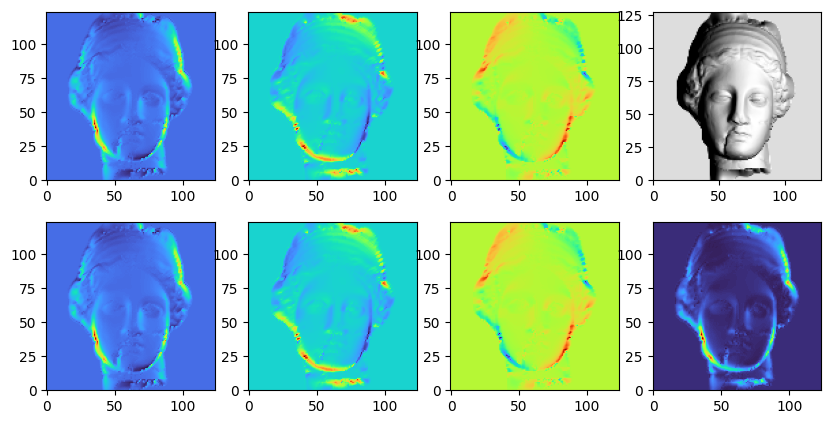

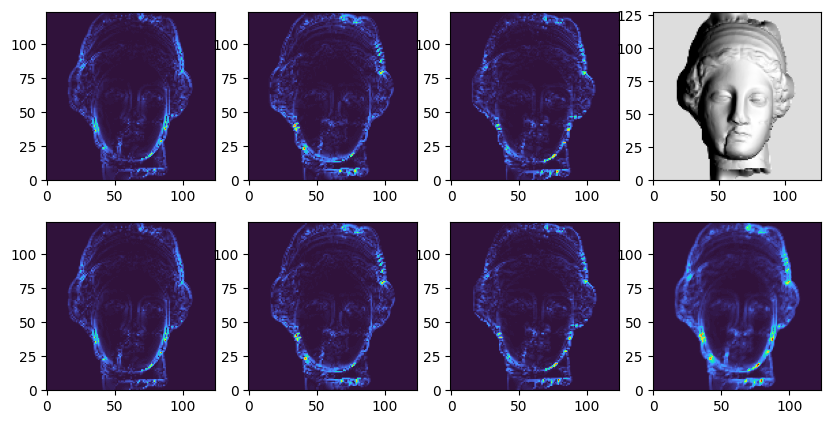

In [ ]:
# Plot the Laplacian
L_hat = cotan_laplacians_from_pq_np(pq_stack_filled, width-2, height-2)
L_hat_reshaped = L_hat.reshape(124, 124, 6)
fig, ax = plt.subplots(2, 4, figsize=(10, 5))

ax[0, 0].imshow(L_hat_reshaped[..., 0], cmap='turbo', origin='lower')
ax[0, 1].imshow(L_hat_reshaped[..., 1], cmap='turbo', origin='lower')
ax[0, 2].imshow(L_hat_reshaped[..., 2], cmap='turbo', origin='lower')
ax[1, 0].imshow(L_hat_reshaped[..., 3], cmap='turbo', origin='lower')
ax[1, 1].imshow(L_hat_reshaped[..., 4], cmap='turbo', origin='lower')
ax[1, 2].imshow(L_hat_reshaped[..., 5], cmap='turbo', origin='lower')
ax[0, 3].imshow(eta_gt_2d, cmap='gray', origin='lower')
ax[1, 3].imshow(L_hat_reshaped.sum(axis=2), cmap='turbo', origin='lower')
plt.show()

lap_gt_interior = lap_gt_reshaped[1:-1, 1:-1, :]
lap_gt_flat = lap_gt_interior.reshape(-1, 6)
lap_error = np.abs(lap_gt_flat - L_hat)

# Reshape lap_error to match the dimensions of lap_gt_reshaped
lap_error_reshaped = lap_error.reshape(height-4, width-4, 6)

# Plot the Laplacian error
fig, ax = plt.subplots(2, 4, figsize=(10, 5))

ax[0, 0].imshow(lap_error_reshaped[..., 0], cmap='turbo', origin='lower')
ax[0, 1].imshow(lap_error_reshaped[..., 1], cmap='turbo', origin='lower')
ax[0, 2].imshow(lap_error_reshaped[..., 2], cmap='turbo', origin='lower')
ax[1, 0].imshow(lap_error_reshaped[..., 3], cmap='turbo', origin='lower')
ax[1, 1].imshow(lap_error_reshaped[..., 4], cmap='turbo', origin='lower')
ax[1, 2].imshow(lap_error_reshaped[..., 5], cmap='turbo', origin='lower')
ax[0, 3].imshow(eta_gt_2d, cmap='gray', origin='lower')
ax[1, 3].imshow(lap_error_reshaped.sum(axis=2), cmap='turbo', origin='lower')
plt.show()

### Fill Ambiguous Pixels

Pixels where both candidates give nearly equal shading error (|η₁ − η₂| < 0.03) are also filled by neighborhood mean.

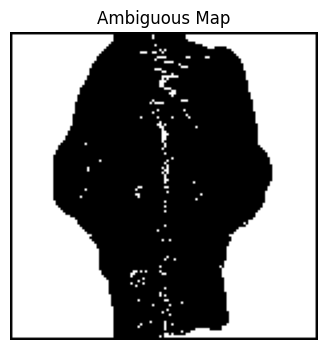

In [ ]:
plt.figure(figsize=(4, 4))
plt.imshow(ambiguous_map, cmap='gray', origin='lower')
plt.title('Ambiguous Map')
plt.axis('off')
plt.show()

In [ ]:
ambiguous_in = ambiguous_map[1:-1, 1:-1]
# Chain on top of invalid-corrected p_filled from the cell above
p_2d = p_filled.copy()
q_2d = q_filled.copy()
p_filled = fill_invalid_by_mean(p_2d, ambiguous_in)
q_filled = fill_invalid_by_mean(q_2d, ambiguous_in)
p_array_1d = p_filled.flatten()
q_array_1d = q_filled.flatten()
pq_stack_filled = np.stack([p_array_1d, q_array_1d, np.ones_like(p_array_1d)], axis=1)

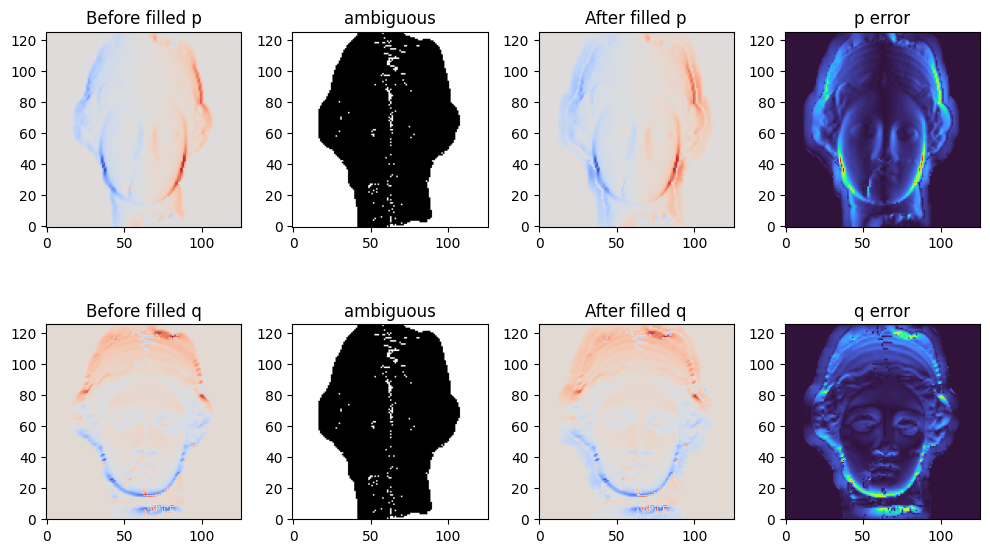

In [ ]:
# Error
p_error_filled = np.abs(p_filled - p_gt_crop)
q_error_filled = np.abs(q_filled - q_gt_crop)

fig, ax = plt.subplots(2, 4, figsize=(10,6))
ax[0,0].imshow(p_2d, origin='lower', cmap='coolwarm'); ax[0,0].set_title('Before filled p')
ax[0,1].imshow(ambiguous_in, origin='lower', cmap='gray'); ax[0,1].set_title('ambiguous')
ax[0,2].imshow(p_filled, origin='lower', cmap='coolwarm'); ax[0,2].set_title('After filled p')
ax[0,3].imshow(p_error_filled, origin='lower', cmap='turbo'); ax[0,3].set_title('p error')
ax[1,0].imshow(q_2d, origin='lower', cmap='coolwarm'); ax[1,0].set_title('Before filled q')
ax[1,1].imshow(ambiguous_in, origin='lower', cmap='gray'); ax[1,1].set_title('ambiguous')
ax[1,2].imshow(q_filled, origin='lower', cmap='coolwarm'); ax[1,2].set_title('After filled q')
ax[1,3].imshow(q_error_filled, origin='lower', cmap='turbo'); ax[1,3].set_title('q error')

plt.tight_layout()
plt.show()


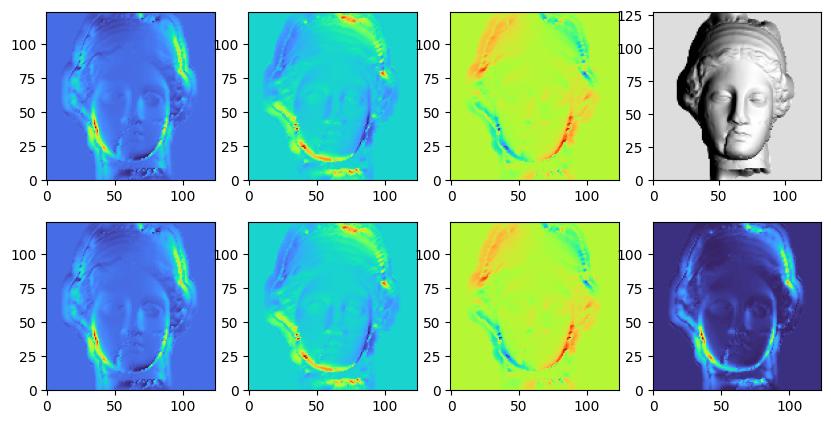

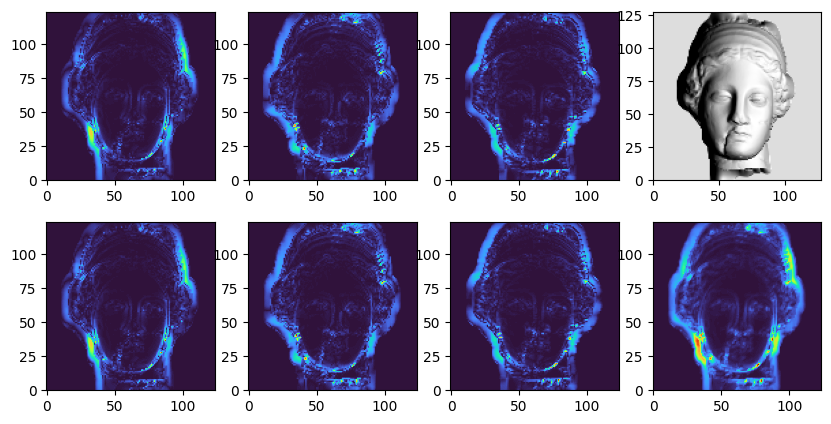

In [ ]:
# Plot the Laplacian
L_hat = cotan_laplacians_from_pq_np(pq_stack_filled, width-2, height-2)
L_hat_reshaped = L_hat.reshape(124, 124, 6)
fig, ax = plt.subplots(2, 4, figsize=(10, 5))

ax[0, 0].imshow(L_hat_reshaped[..., 0], cmap='turbo', origin='lower')
ax[0, 1].imshow(L_hat_reshaped[..., 1], cmap='turbo', origin='lower')
ax[0, 2].imshow(L_hat_reshaped[..., 2], cmap='turbo', origin='lower')
ax[1, 0].imshow(L_hat_reshaped[..., 3], cmap='turbo', origin='lower')
ax[1, 1].imshow(L_hat_reshaped[..., 4], cmap='turbo', origin='lower')
ax[1, 2].imshow(L_hat_reshaped[..., 5], cmap='turbo', origin='lower')
ax[0, 3].imshow(eta_gt_2d, cmap='gray', origin='lower')
ax[1, 3].imshow(L_hat_reshaped.sum(axis=2), cmap='turbo', origin='lower')
plt.show()

lap_gt_interior = lap_gt_reshaped[1:-1, 1:-1, :]
lap_gt_flat = lap_gt_interior.reshape(-1, 6)
lap_error = np.abs(lap_gt_flat - L_hat)

# Reshape lap_error to match the dimensions of lap_gt_reshaped
lap_error_reshaped = lap_error.reshape(height-4, width-4, 6)

# Plot the Laplacian error
fig, ax = plt.subplots(2, 4, figsize=(10, 5))

ax[0, 0].imshow(lap_error_reshaped[..., 0], cmap='turbo', origin='lower')
ax[0, 1].imshow(lap_error_reshaped[..., 1], cmap='turbo', origin='lower')
ax[0, 2].imshow(lap_error_reshaped[..., 2], cmap='turbo', origin='lower')
ax[1, 0].imshow(lap_error_reshaped[..., 3], cmap='turbo', origin='lower')
ax[1, 1].imshow(lap_error_reshaped[..., 4], cmap='turbo', origin='lower')
ax[1, 2].imshow(lap_error_reshaped[..., 5], cmap='turbo', origin='lower')
ax[0, 3].imshow(eta_gt_2d, cmap='gray', origin='lower')
ax[1, 3].imshow(lap_error_reshaped.sum(axis=2), cmap='turbo', origin='lower')
plt.show()

## Step 3 — Global Refinement (Adam)

Jointly optimize all (p, q) to minimize Laplacian reconstruction error + integrability:

```
E     = E_lap + E_int
E_lap = mean ‖L − L̂(p,q)‖²
E_int = mean ‖(pₐ − p) − (q_b − q)‖²
```

### Tensor Setup

The initialized (p, q) are padded by 1 pixel (edge replication) to cover the full H×W grid, then moved to the GPU.  
The neighbor index tensors `idx_i_torch`, `idx_a_torch`, ... precompute the 6 cotangent-neighbor lookups required by `obj_function_pq`.

In [ ]:
# Initial p,q
p_full = np.pad(p_filled, pad_width=1, mode='edge')
q_full = np.pad(q_filled, pad_width=1, mode='edge')
p_init = torch.tensor(p_full.flatten(), dtype=torch.float32).to(device)
q_init = torch.tensor(q_full.flatten(), dtype=torch.float32).to(device)

# Laplacian
lap_torch = torch.from_numpy(lap_gt).float().to(device)

# Neighbor indices
ind_v, ind_a, ind_b, ind_c, ind_d, ind_e, ind_f, ind_g, ind_h = get_ngbr_indices(width, height)
ind_v = np.array(ind_v, dtype=np.int64)
idx_i_torch = torch.tensor(ind_v, dtype=torch.long, device=device)
idx_a_torch = torch.tensor(ind_a, dtype=torch.long, device=device)
idx_b_torch = torch.tensor(ind_b, dtype=torch.long, device=device)
idx_d_torch = torch.tensor(ind_d, dtype=torch.long, device=device)
idx_e_torch = torch.tensor(ind_e, dtype=torch.long, device=device)
idx_f_torch = torch.tensor(ind_f, dtype=torch.long, device=device)


### Optimization

Adam jointly updates all (p, q) across the image.  
`best_p`, `best_q` checkpoint the lowest-loss iterate.  
Convergence is declared when the loss change falls below 1e-12.

Iter: 9990 | Loss: 0.001101: 100%|██████████| 10000/10000 [00:30<00:00, 330.35it/s]


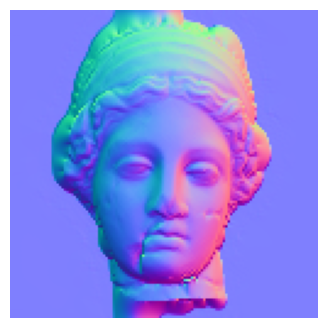

In [ ]:
optimization_params = {
    'adam': {
        'lr': 1e-2,
        'max_iters': 10000
    },
}

best_p, best_q, _, _ = optimize_pq(p_init, q_init, idx_i_torch, idx_a_torch,
                                   idx_b_torch, idx_d_torch, idx_e_torch, idx_f_torch,
                                   lap_torch, width, height, optimization_params)

# Visualize optimized p,q
p_optimized = best_p.detach().cpu().numpy().reshape(height, width)
q_optimized = best_q.detach().cpu().numpy().reshape(height, width)
p_in = p_optimized[1:-1, 1:-1]
q_in = q_optimized[1:-1, 1:-1]
nxny = np.stack([p_in, q_in], axis=-1)  # (h_in, w_in, 2)
ones = np.ones((p_in.shape[0], p_in.shape[1], 1), dtype=p_in.dtype)
normal_map = np.concatenate([nxny, ones], axis=-1)  # (h_in, w_in, 3)
lengths = np.linalg.norm(normal_map, axis=-1, keepdims=True)  # shape (h_in, w_in, 1)
normal_map /= lengths
normal_map = normal_map.astype(np.float32)

normal_img = 0.5 * (normal_map + 1.0)
normal_img = np.clip(normal_img, 0.0, 1.0)

plt.figure(figsize=(4, 4))
plt.imshow(normal_img, origin='lower')
plt.axis("off")
plt.show()

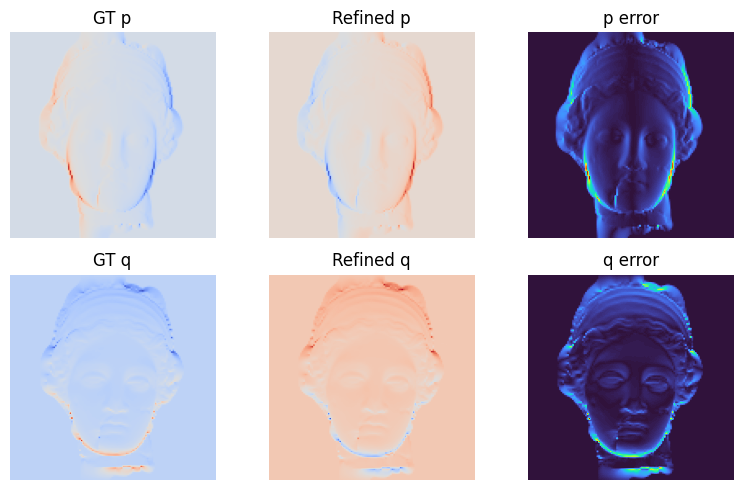

In [ ]:
# Error
p_gt_crop = p_gt_2d[1:-1, 1:-1]
q_gt_crop = q_gt_2d[1:-1, 1:-1]
p_abs_error = np.abs(p_in - p_gt_crop)
q_abs_error = np.abs(q_in - q_gt_crop)

fig, ax = plt.subplots(2, 3, figsize=(8, 5))
ax[0, 0].imshow(p_gt_2d, origin='lower', cmap='coolwarm'); ax[0, 0].set_title('GT p'); ax[0, 0].axis('off')
ax[0, 1].imshow(p_in, origin='lower', cmap='coolwarm'); ax[0, 1].set_title('Refined p'); ax[0, 1].axis('off')
ax[1, 0].imshow(q_gt_2d, origin='lower', cmap='coolwarm'); ax[1, 0].set_title('GT q'); ax[1, 0].axis('off')
ax[1, 1].imshow(q_in, origin='lower', cmap='coolwarm'); ax[1, 1].set_title('Refined q'); ax[1, 1].axis('off')
ax[0, 2].imshow(p_abs_error, origin='lower', cmap='turbo'); ax[0, 2].set_title('p error'); ax[0, 2].axis('off')
ax[1, 2].imshow(q_abs_error, origin='lower', cmap='turbo'); ax[1, 2].set_title('q error'); ax[1, 2].axis('off')

plt.tight_layout()
plt.show()

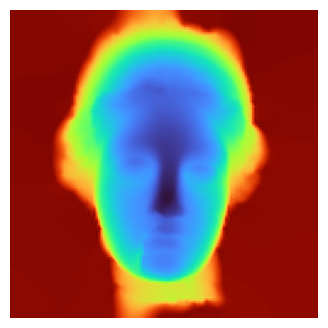

In [ ]:
fx = p_in.reshape((height-2, width-2))
fy = q_in.reshape((height-2, width-2))
depth_map_est = np.real(frankotchellappa(fx, fy))

plt.figure(figsize=(4, 4))
plt.imshow(depth_map_est, origin='lower', cmap='turbo')
plt.axis("off")
plt.show()


In [ ]:
try:
    import meshplot as mp
    H, W = depth_map_est.shape
    yy, xx = np.meshgrid(np.arange(H), np.arange(W), indexing="ij")
    verts = np.stack([xx.reshape(-1), yy.reshape(-1), -depth_map_est.reshape(-1)], axis=1)
    faces = []
    for y in range(H - 1):
        for x in range(W - 1):
            v0 = y * W + x
            faces += [[v0, v0 + 1, v0 + W], [v0 + 1, v0 + W + 1, v0 + W]]
    mp.plot(verts, np.array(faces), c=verts[:, 2], shading={"wireframe": False})
except ImportError:
    print("meshplot not installed — skipping 3D visualization")


## Step 4 — Results

Final evaluation against GT:

- **Normal map** — rendered as RGB with object mask alpha
- **p, q error maps** — per-pixel absolute error vs GT
- **Depth map** — integrated via Frankot-Chellappa (FFT-based)
- **Shading** — re-rendered from estimated (p, q) and estimated (pₛ, qₛ)

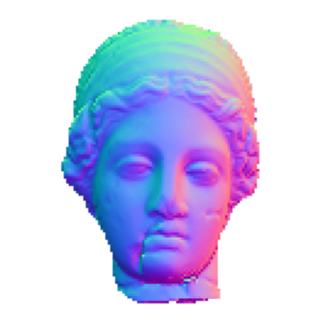

In [ ]:
mask_in = mask2d[1:-1, 1:-1].astype(bool)
alpha = (~mask_in).astype(np.float32)
normal_rgba = np.dstack([normal_img, alpha])

plt.figure(figsize=(4,4))
plt.imshow(normal_rgba, origin="lower")
plt.axis("off")
plt.show()


In [ ]:
mask_in = mask2d[1:-1, 1:-1].astype(bool)
valid = ~mask_in

def masked_nan(x, valid):
    x = x.astype(np.float32).copy()
    x[~valid] = np.nan
    return x

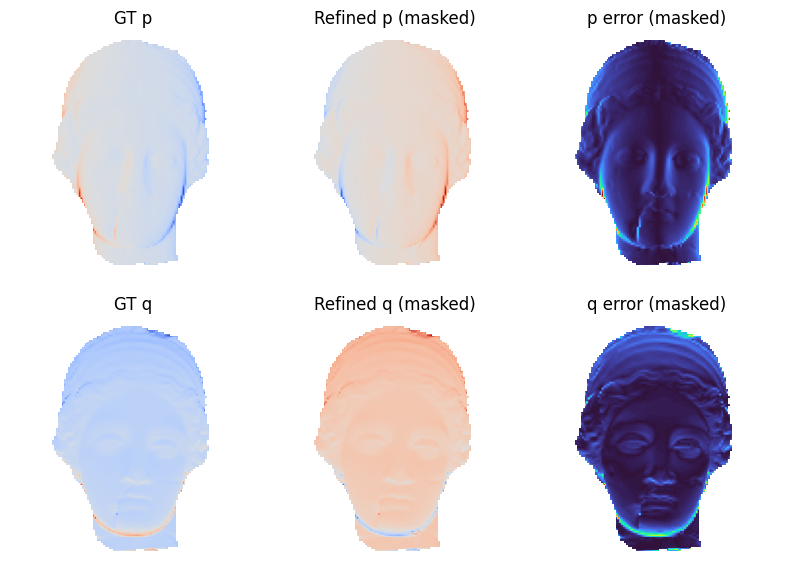

In [ ]:
p_gt_crop = p_gt_2d[1:-1, 1:-1]
q_gt_crop = q_gt_2d[1:-1, 1:-1]
p_abs_error = np.abs(p_in - p_gt_crop)
q_abs_error = np.abs(q_in - q_gt_crop)

fig, ax = plt.subplots(2, 3, figsize=(8, 6))
ax[0, 0].imshow(masked_nan(p_gt_2d[1:-1, 1:-1], valid), origin='lower', cmap='coolwarm'); ax[0, 0].set_title('GT p'); ax[0, 0].axis('off')
ax[0, 1].imshow(masked_nan(p_in, valid), origin='lower', cmap='coolwarm'); ax[0, 1].set_title('Refined p (masked)'); ax[0, 1].axis('off')
ax[1, 0].imshow(masked_nan(q_gt_2d[1:-1, 1:-1], valid), origin='lower', cmap='coolwarm'); ax[1, 0].set_title('GT q'); ax[1, 0].axis('off')
ax[1, 1].imshow(masked_nan(q_in, valid), origin='lower', cmap='coolwarm'); ax[1, 1].set_title('Refined q (masked)'); ax[1, 1].axis('off')
ax[0, 2].imshow(masked_nan(p_abs_error, valid), origin='lower', cmap='turbo'); ax[0, 2].set_title('p error (masked)'); ax[0, 2].axis('off')
ax[1, 2].imshow(masked_nan(q_abs_error, valid), origin='lower', cmap='turbo'); ax[1, 2].set_title('q error (masked)'); ax[1, 2].axis('off')

plt.tight_layout()
plt.show()


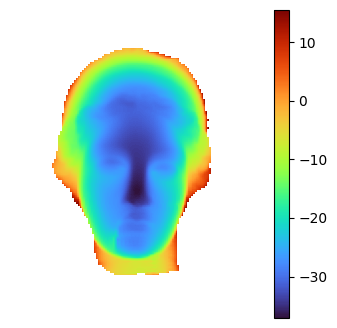

In [ ]:
fx = p_in.reshape((height-2, width-2))
fy = q_in.reshape((height-2, width-2))

z_inner = np.real(frankotchellappa(fx, fy))  # (h-2, w-2)
mask_in = mask2d[1:-1, 1:-1].astype(bool)
valid = ~mask_in

z_vis = z_inner.copy().astype(np.float32)
z_vis[~valid] = np.nan
plt.figure(figsize=(4, 4))
plt.imshow(z_vis, origin='lower', cmap='turbo')
plt.axis("off")
plt.colorbar()
plt.show()


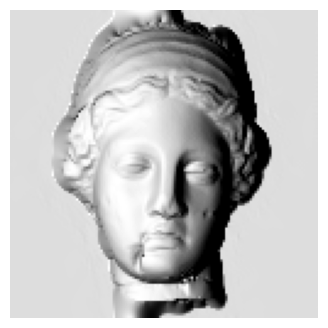

In [ ]:
shading_rend = compute_shading_value(p_in, q_in, ps_gt, qs_gt)
plt.figure(figsize=(4, 4))
plt.imshow(shading_rend, cmap='gray', origin='lower')
plt.axis("off")
plt.show()